# Projeto Final — Caso Principal: CallMeMaybe (Identificação de Operadores Ineficientes)

- **Analista:** Luiz Almeida
- **Sprint:** 14 — Projeto Final (TripleTen)
- **Data:** 21/09/2026
- **Links do Projeto:**
  - **Arquivo Completo (.zip no Google Drive):** [GOOGLE_DRIVE](https://drive.google.com/file/d/1pewk7eg9mvr2sliBkd1xM5mDGOkCO7p-/view?usp=drive_link)
  - **Dashboard Interativo (Tableau Public):** [Painel CallMeMaybe](https://public.tableau.com/views/CallMeMaybe-PaineldeDesempenhoOperacional/Dashboard1?:language=pt-BR&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

## Contexto e Objetivos do Estudo


A **CallMeMaybe** é uma operadora de telefonia virtual (VoIP) focada no segmento corporativo (B2B). A plataforma desenvolveu uma ferramenta analítica voltada a supervisores operacionais para identificar operadores com desempenho abaixo do esperado. 

De acordo com as regras de negócio, um operador é considerado **ineficiente** quando apresenta pelo menos um dos seguintes fatores:
1. Alto volume de chamadas recebidas perdidas (tanto externas quanto internas);
2. Tempo de espera elevado dos clientes nas chamadas recebidas;
3. Baixa produtividade no volume de chamadas de saída realizadas, no caso de operadores designados para prospecção/ativação.

Este notebook implementa a execução técnica integral do plano de ação aprovado na Decomposição de Tarefas: carregamento, sanitização, engenharia de variáveis, exploração estatística, validação formal das cinco hipóteses (H1 a H5) e formulação de recomendações de negócio.


## 1. IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÃO DO AMBIENTE

In [1]:
# ==============================================================================
# IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÃO DO AMBIENTE
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import warnings

# Supressão de avisos não críticos para manter a visualização limpa
warnings.filterwarnings('ignore')

# Configurações visuais padronizadas para os gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_palette('Set2')

# Configurações de exibição do Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print("Ambiente configurado e bibliotecas importadas com sucesso!")

Ambiente configurado e bibliotecas importadas com sucesso!


## 2. Carregamento e Inspeção Inicial dos Dados

Nesta etapa (Ação A1), carregamos os dois datasets fornecidos pela CallMeMaybe:
- `telecom_dataset_new.csv`: Dados transacionais de chamadas telefônicas agrupados por cliente, operador e data.
- `telecom_clients.csv`: Dados cadastrais dos clientes corporativos (plano tarifário contratado e data de início).

In [2]:
# ==============================================================================
# CARREGAMENTO DOS DATASETS (Ação A1)
# ==============================================================================

# Tentativa de carregamento local ou via caminho padrão da plataforma
try:
    df_usage = pd.read_csv('/datasets/telecom_dataset_new.csv')
    df_clients = pd.read_csv('/datasets/telecom_clients.csv')
except FileNotFoundError:
    df_usage = pd.read_csv('telecom_dataset_new.csv')
    df_clients = pd.read_csv('telecom_clients.csv')

# Exibição de dimensões dos datasets
print(f"Dimensões do Dataset de Uso (telecom_dataset_new): {df_usage.shape[0]} linhas e {df_usage.shape[1]} colunas.")
print(f"Dimensões do Dataset de Clientes (telecom_clients): {df_clients.shape[0]} linhas e {df_clients.shape[1]} colunas.")

print("\n--- Primeiras 5 linhas do Dataset de Uso ---")
display(df_usage.head(5))

print("\n--- Primeiras 5 linhas do Dataset de Clientes ---")
display(df_clients.head(5))

print("\n--- Informações Estruturais do Dataset de Uso ---")
df_usage.info()

print("\n--- Informações Estruturais do Dataset de Clientes ---")
df_clients.info()

Dimensões do Dataset de Uso (telecom_dataset_new): 53902 linhas e 9 colunas.
Dimensões do Dataset de Clientes (telecom_clients): 732 linhas e 3 colunas.

--- Primeiras 5 linhas do Dataset de Uso ---


,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,880022.000,True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,880020.000,True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,880020.000,False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,880022.000,True,3,0,25



--- Primeiras 5 linhas do Dataset de Clientes ---


,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16



--- Informações Estruturais do Dataset de Uso ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  object 
 2   direction            53902 non-null  object 
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(3)
memory usage: 3.3+ MB

--- Informações Estruturais do Dataset de Clientes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       -

## 3. Limpeza e Pré-processamento dos Dados

Conforme delineado no plano de ação:
* **A2 e A5:** Investigação e tratamento de valores nulos, especialmente na coluna `operator_id`. Em chamadas externas recebidas que foram perdidas ou não atendidas, a ausência de operador é esperada (a chamada tocou no sistema antes de ser distribuída a uma pessoa).
* **A3:** Investigação e remoção de registros duplicados idênticos.
* **A4:** Conversão de formatos temporais (`date` e `date_start` para datetime) e de tipos lógicos (`internal` e `is_missed_call` para booleano).

In [3]:
# ==============================================================================
# DIAGNÓSTICO DE NULOS E DUPLICATAS (Ações A2 e A3)
# ==============================================================================

print("=== VALORES AUSENTES ANTES DO TRATAMENTO ===")
print("\nDataset de Uso:")
print(df_usage.isnull().sum())
print("\nDataset de Clientes:")
print(df_clients.isnull().sum())

# Verificação de linhas totalmente duplicadas
dup_usage = df_usage.duplicated().sum()
dup_clients = df_clients.duplicated().sum()

print(f"\nLinhas totalmente duplicadas no Dataset de Uso: {dup_usage}")
print(f"Linhas totalmente duplicadas no Dataset de Clientes: {dup_clients}")

# Remoção de duplicatas exatas no dataset de uso
if dup_usage > 0:
    df_usage = df_usage.drop_duplicates().reset_index(drop=True)
    print(f"-> {dup_usage} registros duplicados removidos com sucesso do dataset de uso.")

# ==============================================================================
# CONVERSÃO DE TIPOS (Ação A4)
# ==============================================================================

# Conversão de datas
df_usage['date'] = pd.to_datetime(df_usage['date'])
df_clients['date_start'] = pd.to_datetime(df_clients['date_start'])

# Conversão de variáveis lógicas
df_usage['is_missed_call'] = df_usage['is_missed_call'].astype(bool)

# Tratamento de internal: preencher eventuais nulos com False e converter para booleano
df_usage['internal'] = df_usage['internal'].fillna(False).astype(bool)

# ==============================================================================
# TRATAMENTO DE OPERATOR_ID (Ação A5)
# ==============================================================================

# Chamadas com operator_id nulo
nulos_operador = df_usage['operator_id'].isnull().sum()
print(f"\nTotal de registros sem identificação de operador: {nulos_operador} ({nulos_operador / len(df_usage):.2%})")

# Distribuição das chamadas sem operador por direção
print("\nDireção das chamadas com operator_id nulo:")
print(df_usage[df_usage['operator_id'].isnull()]['direction'].value_counts())

print("\nStatus de perda (is_missed_call) para chamadas com operator_id nulo:")
print(df_usage[df_usage['operator_id'].isnull()]['is_missed_call'].value_counts())

# Registros sem operator_id não podem ser atribuídos a operadores individuais.
# Mantemos o dataset transacional integral para métricas agregadas por cliente,
# e criamos uma visão filtrada para avaliações a nível de operador.

=== VALORES AUSENTES ANTES DO TRATAMENTO ===

Dataset de Uso:
user_id                   0
date                      0
direction                 0
internal                117
operator_id            8172
is_missed_call            0
calls_count               0
call_duration             0
total_call_duration       0
dtype: int64

Dataset de Clientes:
user_id        0
tariff_plan    0
date_start     0
dtype: int64

Linhas totalmente duplicadas no Dataset de Uso: 4900
Linhas totalmente duplicadas no Dataset de Clientes: 0
-> 4900 registros duplicados removidos com sucesso do dataset de uso.

Total de registros sem identificação de operador: 7456 (15.22%)

Direção das chamadas com operator_id nulo:
in     7270
out     186
Name: direction, dtype: int64

Status de perda (is_missed_call) para chamadas com operator_id nulo:
True     7343
False     113
Name: is_missed_call, dtype: int64


## 4. Integração dos Dados e Engenharia de Variáveis (Features)

* **A7:** Junção (`left join`) entre o dataset de uso e o cadastro de clientes por meio da chave `user_id`[cite: 10].
* **A8:** Criação das colunas derivadas:
  * `wait_time`: Tempo de espera calculado como a diferença entre a duração total e a duração efetiva de conversação: `total_call_duration - call_duration`[cite: 10].
  * `tenure_days`: Antiguidade do cliente calculada como o intervalo entre a data da chamada e a data de contratação (`date_start`)[cite: 10].
  * `month`: Período mensal da atividade[cite: 10].

In [5]:
# ==============================================================================
# MERGE DOS DATASETS E ENGENHARIA DE ATRIBUTOS (Ações A7 e A8) - CORRIGIDO
# ==============================================================================

# 1. Garantir a conversão estrita de tipos de data antes do merge
df_usage['date'] = pd.to_datetime(df_usage['date'])
df_clients['date_start'] = pd.to_datetime(df_clients['date_start'])

# Remover qualquer fuso horário (timezone) caso exista, para permitir operações de subtração
if df_usage['date'].dt.tz is not None:
    df_usage['date'] = df_usage['date'].dt.tz_localize(None)
if df_clients['date_start'].dt.tz is not None:
    df_clients['date_start'] = df_clients['date_start'].dt.tz_localize(None)

# 2. Junção dos datasets por user_id (Ação A7)
df_merged = df_usage.merge(df_clients, on='user_id', how='left')

# Garantir que após o merge as colunas continuem no formato datetime compatível
df_merged['date'] = pd.to_datetime(df_merged['date'])
df_merged['date_start'] = pd.to_datetime(df_merged['date_start'])

# 3. Cálculo do Tempo de Espera (wait_time em segundos)
df_merged['wait_time'] = df_merged['total_call_duration'] - df_merged['call_duration']

# Ajustar eventuais valores negativos pontuais para 0
df_merged['wait_time'] = df_merged['wait_time'].clip(lower=0)

# 4. Cálculo da Antiguidade do Cliente (tenure_days em dias)
df_merged['tenure_days'] = (df_merged['date'] - df_merged['date_start']).dt.days

# Tratar possíveis nulos de tenure caso algum cliente não tenha data de início
df_merged['tenure_days'] = df_merged['tenure_days'].fillna(0).astype(int)

# 5. Período mensal e dia da semana
df_merged['month'] = df_merged['date'].dt.to_period('M')
df_merged['day_of_week'] = df_merged['date'].dt.day_name()

print("--- Visão Geral do Dataset Integrado e Tratado ---")
display(df_merged.head(5))

print("\nEstatísticas básicas das variáveis contínuas e derivadas:")
display(df_merged[['calls_count', 'call_duration', 'total_call_duration', 'wait_time', 'tenure_days']].describe())

# ==============================================================================
# EXPORTAÇÃO INTERMEDIÁRIA (Ação A9)
# ==============================================================================
df_merged.to_csv('telecom_merged.csv', index=False)
print("\n-> Arquivo intermediário 'telecom_merged.csv' gerado e salvo com sucesso!")

--- Visão Geral do Dataset Integrado e Tratado ---


,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration,tariff_plan,date_start,wait_time,tenure_days,month,day_of_week
0,166377,2019-08-04,in,False,NaN,True,2,0,4,B,2019-08-01,4,3,2019-08,Sunday
1,166377,2019-08-05,out,True,880022.000,True,3,0,5,B,2019-08-01,5,4,2019-08,Monday
2,166377,2019-08-05,out,True,880020.000,True,1,0,1,B,2019-08-01,1,4,2019-08,Monday
3,166377,2019-08-05,out,True,880020.000,False,1,10,18,B,2019-08-01,8,4,2019-08,Monday
4,166377,2019-08-05,out,False,880022.000,True,3,0,25,B,2019-08-01,25,4,2019-08,Monday



Estatísticas básicas das variáveis contínuas e derivadas:


,calls_count,call_duration,total_call_duration,wait_time,tenure_days
count,49002.000,49002.000,49002.000,49002.000,49002.000
mean,16.463,866.282,1156.558,290.276,44.024
std,63.604,3775.503,4451.474,1132.155,27.023
min,1.000,0.000,0.000,0.000,0.000
25%,1.000,0.000,46.000,17.000,22.000
50%,4.000,37.000,208.000,55.000,40.000
75%,12.000,570.000,901.000,200.000,63.000
max,4817.000,144395.000,166155.000,46474.000,119.000



-> Arquivo intermediário 'telecom_merged.csv' gerado e salvo com sucesso!


## 5. Análise Exploratória dos Dados (EDA)

Nesta seção, exploramos o comportamento operacional da base de telefonia CallMeMaybe:
1. **Distribuição das Variáveis Contínuas (A10):** Avaliação de dispersão, assimetria e presença de outliers em volume de chamadas, tempos de duração e tempo de espera.
2. **Distribuição Transacional (A11):** Frequência de chamadas por direção (entrada/saída), natureza (interna/externa) e proporção de perda.
3. **Padrões Temporais (A16):** Comportamento diário e semanal do volume e tempo de espera.
4. **Segmentação por Planos e Antiguidade (A14 e A15):** Diagnóstico preliminar de diferenças operacionais entre os clientes.

=== ESTATÍSTICA DESCRITIVA DETALHADA ===


,calls_count,call_duration,total_call_duration,wait_time
count,49002.000,49002.000,49002.000,49002.000
mean,16.463,866.282,1156.558,290.276
std,63.604,3775.503,4451.474,1132.155
min,1.000,0.000,0.000,0.000
1%,1.000,0.000,0.000,0.000
5%,1.000,0.000,3.000,2.000
25%,1.000,0.000,46.000,17.000
50%,4.000,37.000,208.000,55.000
75%,12.000,570.000,901.000,200.000
95%,62.000,3725.950,4531.000,1163.000


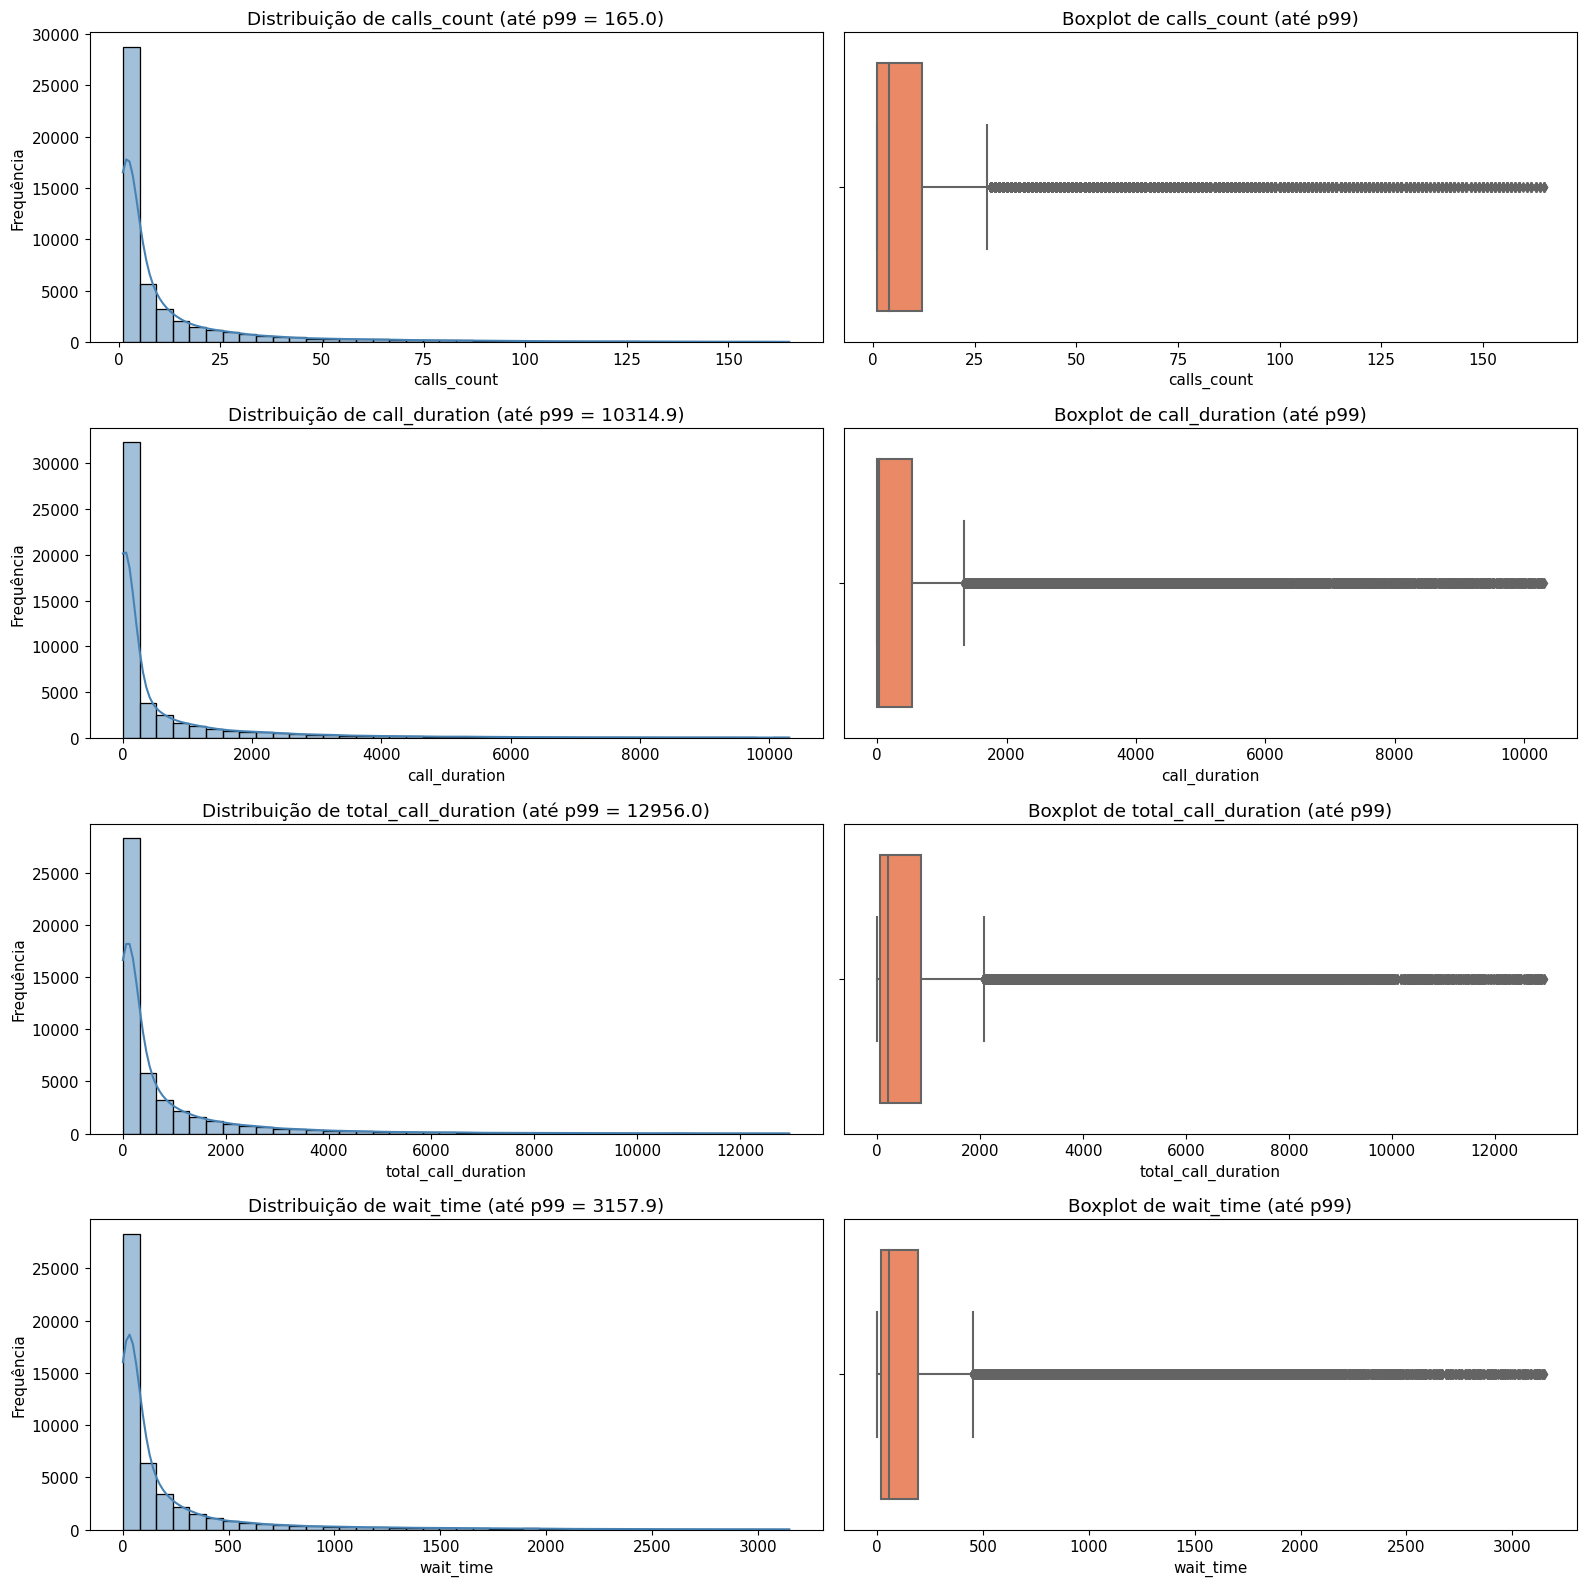

In [6]:
# ==============================================================================
# ANÁLISE DESCRITIVA E DISTRIBUIÇÃO DAS VARIÁVEIS CONTÍNUAS (Ação A10)
# ==============================================================================

metricas_continuas = ['calls_count', 'call_duration', 'total_call_duration', 'wait_time']

print("=== ESTATÍSTICA DESCRITIVA DETALHADA ===")
display(df_merged[metricas_continuas].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

# Plotagem dos Histogramas e Boxplots
fig, axes = plt.subplots(4, 2, figsize=(16, 16))

for idx, col in enumerate(metricas_continuas):
    # Histograma com limite superior de 99% para visualização clara (evitando distorção de cauda longa)
    limite_sup = df_merged[col].quantile(0.99)
    dados_filtrados = df_merged[df_merged[col] <= limite_sup][col]
    
    # Histograma (lado esquerdo)
    sns.histplot(dados_filtrados, bins=40, kde=True, ax=axes[idx, 0], color='steelblue')
    axes[idx, 0].set_title(f'Distribuição de {col} (até p99 = {limite_sup:.1f})')
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel('Frequência')
    
    # Boxplot (lado direito)
    sns.boxplot(x=dados_filtrados, ax=axes[idx, 1], color='coral')
    axes[idx, 1].set_title(f'Boxplot de {col} (até p99)')
    axes[idx, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

### 5.1 Frequência Transacional por Direção, Tipo e Status de Atendimento (A11)

Avaliamos as proporções globais de:
* Direção da chamada: Recebida (`in`) vs. Realizada (`out`).
* Tipo da chamada: Externa vs. Interna (`internal`).
* Taxa de Chamadas Perdidas (`is_missed_call`).

--- Volume Total de Chamadas por Direção ---
Direção 'in': 197,845 chamadas (24.52%)
Direção 'out': 608,864 chamadas (75.48%)

--- Volume Total de Chamadas por Tipo ---
Tipo 'Externa': 792,054 chamadas (98.18%)
Tipo 'Interna': 14,655 chamadas (1.82%)

--- Volume Total de Chamadas por Status ---
Status 'Atendida': 430,791 chamadas (53.40%)
Status 'Perdida': 375,918 chamadas (46.60%)


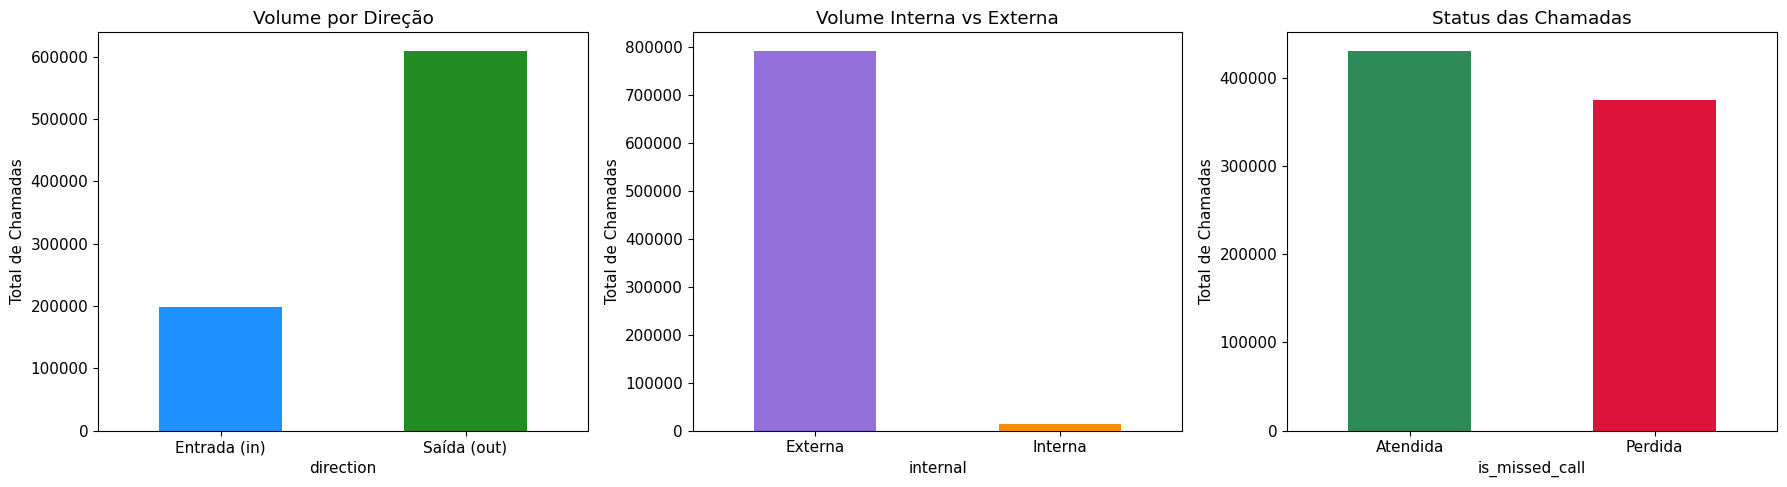

In [7]:
# ==============================================================================
# DISTRIBUIÇÃO TRANSACIONAL DAS CHAMADAS (Ação A11)
# ==============================================================================

# Total de chamadas somando o calls_count real
total_volume = df_merged['calls_count'].sum()

# 1. Por Direção
vol_direction = df_merged.groupby('direction')['calls_count'].sum()
print("--- Volume Total de Chamadas por Direção ---")
for k, v in vol_direction.items():
    print(f"Direção '{k}': {v:,} chamadas ({v / total_volume:.2%})")

# 2. Por Tipo Interna vs Externa
vol_internal = df_merged.groupby('internal')['calls_count'].sum()
print("\n--- Volume Total de Chamadas por Tipo ---")
for k, v in vol_internal.items():
    tipo_nome = "Interna" if k else "Externa"
    print(f"Tipo '{tipo_nome}': {v:,} chamadas ({v / total_volume:.2%})")

# 3. Por Status de Perda
vol_missed = df_merged.groupby('is_missed_call')['calls_count'].sum()
print("\n--- Volume Total de Chamadas por Status ---")
for k, v in vol_missed.items():
    status_nome = "Perdida" if k else "Atendida"
    print(f"Status '{status_nome}': {v:,} chamadas ({v / total_volume:.2%})")

# Visualização gráfica comparativa
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico Direção
vol_direction.plot(kind='bar', ax=axes[0], color=['dodgerblue', 'forestgreen'], rot=0)
axes[0].set_title('Volume por Direção')
axes[0].set_ylabel('Total de Chamadas')
axes[0].set_xticklabels(['Entrada (in)', 'Saída (out)'])

# Gráfico Interna vs Externa
vol_internal.plot(kind='bar', ax=axes[1], color=['mediumpurple', 'darkorange'], rot=0)
axes[1].set_title('Volume Interna vs Externa')
axes[1].set_ylabel('Total de Chamadas')
axes[1].set_xticklabels(['Externa', 'Interna'])

# Gráfico Atendidas vs Perdidas
vol_missed.plot(kind='bar', ax=axes[2], color=['seagreen', 'crimson'], rot=0)
axes[2].set_title('Status das Chamadas')
axes[2].set_ylabel('Total de Chamadas')
axes[2].set_xticklabels(['Atendida', 'Perdida'])

plt.tight_layout()
plt.show()

### 5.2 Segmentação Operacional e Análise Temporal (A14 a A17)

Investigamos como as métricas centrais variam em função de:
* **Plano Tarifário (A14):** Comportamento dos clientes nos planos A, B e C.
* **Antiguidade (A15):** Relação entre o tempo de casa do cliente corporativo e a eficiência do serviço.
* **Série Temporal (A16):** Variação ao longo do período observado.
* **Matriz de Correlação Geral (A17):** Relações lineares e não lineares entre as variáveis.

--- Métricas Operacionais por Plano Tarifário (A14) ---


,tariff_plan,total_chamadas,taxa_perdidas,tempo_medio_espera,duracao_media
0,A,439650,48.777,598.625,1610.243
1,B,163573,41.872,162.496,601.914
2,C,203486,45.692,181.680,562.684


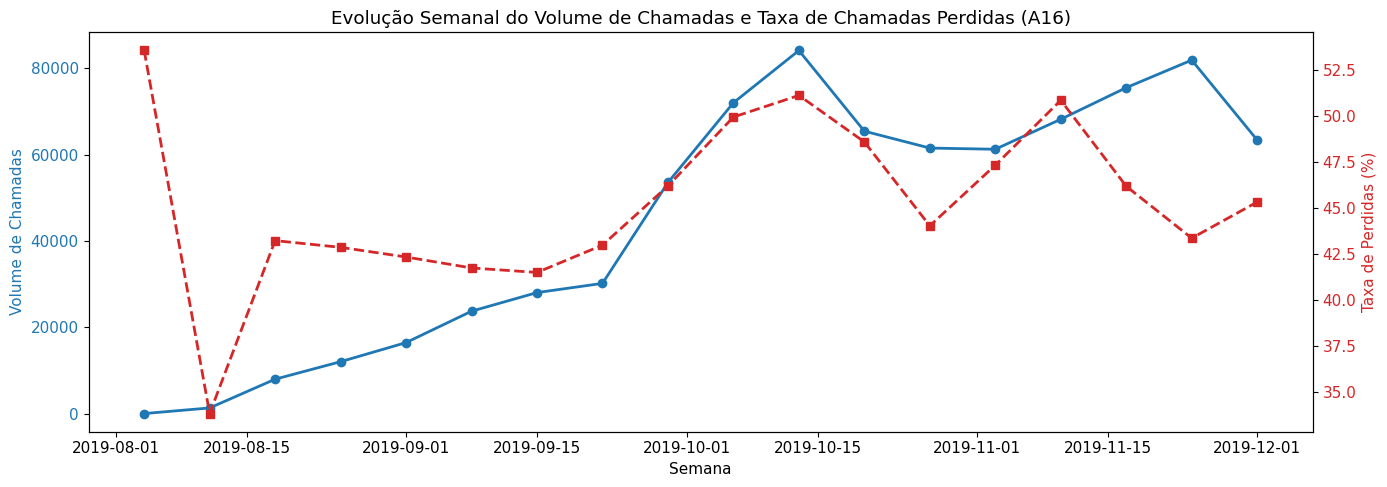

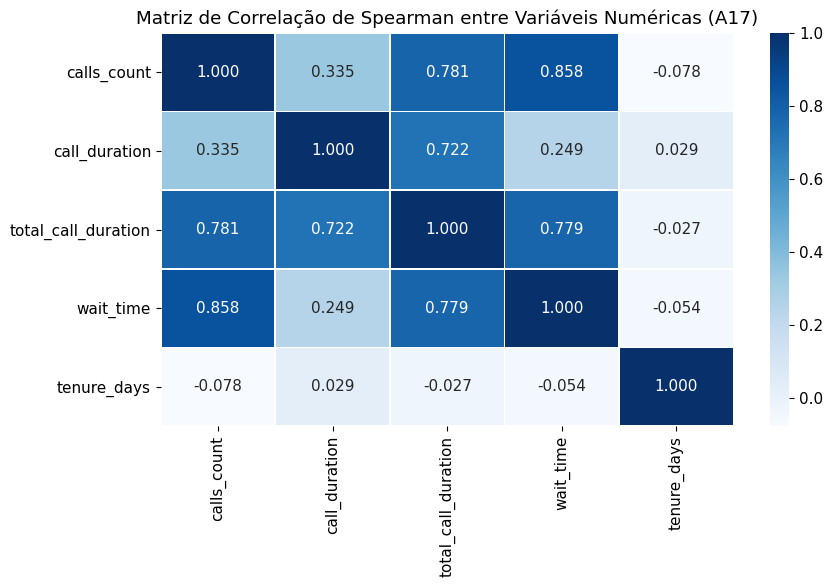

In [9]:
# ==============================================================================
# ANÁLISE POR PLANO TARIFÁRIO, ANTIGUIDADE E SÉRIE TEMPORAL (Ações A14 a A17) - CORRIGIDO
# ==============================================================================

# 0. Criação de coluna auxiliar ponderada para chamadas perdidas
df_merged['missed_calls_count'] = df_merged['is_missed_call'].astype(int) * df_merged['calls_count']

# 1. Comparação por Plano Tarifário (Ação A14)
df_planos = df_merged.groupby('tariff_plan').agg(
    total_chamadas=('calls_count', 'sum'),
    total_perdidas=('missed_calls_count', 'sum'),
    tempo_medio_espera=('wait_time', 'mean'),
    duracao_media=('call_duration', 'mean')
).reset_index()

df_planos['taxa_perdidas'] = (df_planos['total_perdidas'] / df_planos['total_chamadas']) * 100

print("--- Métricas Operacionais por Plano Tarifário (A14) ---")
display(df_planos[['tariff_plan', 'total_chamadas', 'taxa_perdidas', 'tempo_medio_espera', 'duracao_media']])

# 2. Série Temporal Semanal do Volume e Tempo de Espera (Ação A16)
df_temporal = df_merged.groupby(pd.Grouper(key='date', freq='W')).agg(
    total_chamadas=('calls_count', 'sum'),
    total_perdidas=('missed_calls_count', 'sum'),
    tempo_medio_espera=('wait_time', 'mean')
).reset_index()

df_temporal['taxa_perdidas'] = (df_temporal['total_perdidas'] / df_temporal['total_chamadas']) * 100

# Gráfico da evolução temporal
fig, ax1 = plt.subplots(figsize=(14, 5))
color = 'tab:blue'
ax1.set_xlabel('Semana')
ax1.set_ylabel('Volume de Chamadas', color=color)
ax1.plot(df_temporal['date'], df_temporal['total_chamadas'], color=color, marker='o', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Taxa de Perdidas (%)', color=color)
ax2.plot(df_temporal['date'], df_temporal['taxa_perdidas'], color=color, marker='s', linestyle='--', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Evolução Semanal do Volume de Chamadas e Taxa de Chamadas Perdidas (A16)')
plt.tight_layout()
plt.show()

# 3. Matriz de Correlação das Variáveis Numéricas (Ação A17)
cols_corr = ['calls_count', 'call_duration', 'total_call_duration', 'wait_time', 'tenure_days']
matriz_corr = df_merged[cols_corr].corr(method='spearman')

plt.figure(figsize=(9, 6))
sns.heatmap(matriz_corr, annot=True, cmap='Blues', fmt='.3f', linewidths=0.5)
plt.title('Matriz de Correlação de Spearman entre Variáveis Numéricas (A17)')
plt.tight_layout()
plt.show()

## 6. Mapeamento de KPIs e Identificação de Operadores Ineficientes

Nesta seção consolidamos as métricas no nível de granularidade do **operador** (`operator_id`):
* Filtramos os registros com identificação válida de operador (`operator_id.notnull()`).
* Calculamos para cada operador:
  * Volume total de chamadas recebidas e volume de chamadas recebidas perdidas.
  * **Taxa de chamadas perdidas (%)**.
  * **Tempo médio de espera em chamadas recebidas (segundos)**.
  * Volume total e média diária de **chamadas de saída (ativas)**.
  * Duração média efetiva de atendimento.
* Estabelecemos os limiares estatísticos (quartis) para classificar os operadores em **eficientes** ou **ineficientes**.

In [10]:
# ==============================================================================
# CONSOLIDAÇÃO DE DADOS NO NÍVEL DO OPERADOR
# ==============================================================================

# Filtrar apenas chamadas associadas a operadores identificados
df_ops = df_merged[df_merged['operator_id'].notnull()].copy()
df_ops['operator_id'] = df_ops['operator_id'].astype(int)

# 1. Agregação Geral de Chamadas por Operador
# Total de chamadas e dias trabalhados
resumo_geral = df_ops.groupby('operator_id').agg(
    total_chamadas=('calls_count', 'sum'),
    dias_ativos=('date', 'nunique'),
    user_id=('user_id', 'first'),
    tariff_plan=('tariff_plan', 'first'),
    tenure_dias=('tenure_days', 'mean')
)

# 2. Métricas de Chamadas Recebidas (direction == 'in')
df_in = df_ops[df_ops['direction'] == 'in']
resumo_in = df_in.groupby('operator_id').agg(
    in_total_chamadas=('calls_count', 'sum'),
    in_chamadas_perdidas=('missed_calls_count', 'sum'),
    in_tempo_espera_total=('wait_time', 'sum'),
    in_tempo_espera_medio=('wait_time', 'mean'),
    in_duracao_media=('call_duration', 'mean')
)

# Taxa de perdidas nas chamadas de entrada
resumo_in['taxa_perdidas_in'] = (resumo_in['in_chamadas_perdidas'] / resumo_in['in_total_chamadas']) * 100

# 3. Métricas de Chamadas de Saída (direction == 'out')
df_out = df_ops[df_ops['direction'] == 'out']
resumo_out = df_out.groupby('operator_id').agg(
    out_total_chamadas=('calls_count', 'sum'),
    out_tempo_espera_medio=('wait_time', 'mean'),
    out_duracao_media=('call_duration', 'mean')
)

# 4. Junção de todas as visões na tabela mestra de operadores
df_kpi_operadores = resumo_geral.join(resumo_in, how='left').join(resumo_out, how='left')

# Preenchimento de nulos para operadores que atuam somente em uma das direções
df_kpi_operadores['in_total_chamadas'] = df_kpi_operadores['in_total_chamadas'].fillna(0)
df_kpi_operadores['in_chamadas_perdidas'] = df_kpi_operadores['in_chamadas_perdidas'].fillna(0)
df_kpi_operadores['taxa_perdidas_in'] = df_kpi_operadores['taxa_perdidas_in'].fillna(0)
df_kpi_operadores['in_tempo_espera_medio'] = df_kpi_operadores['in_tempo_espera_medio'].fillna(0)

df_kpi_operadores['out_total_chamadas'] = df_kpi_operadores['out_total_chamadas'].fillna(0)
df_kpi_operadores['out_chamadas_por_dia'] = df_kpi_operadores['out_total_chamadas'] / df_kpi_operadores['dias_ativos']

# Taxa de chamadas perdidas geral (entradas + saídas não atendidas)
resumo_perdidas_geral = df_ops.groupby('operator_id').agg(
    total_perdidas=('missed_calls_count', 'sum'),
    tempo_espera_geral=('wait_time', 'mean')
)
df_kpi_operadores['total_perdidas'] = resumo_perdidas_geral['total_perdidas']
df_kpi_operadores['taxa_perdidas_geral'] = (df_kpi_operadores['total_perdidas'] / df_kpi_operadores['total_chamadas']) * 100
df_kpi_operadores['tempo_espera_geral'] = resumo_perdidas_geral['tempo_espera_geral']

print(f"Total de operadores únicos identificados na base: {len(df_kpi_operadores)}")
print("\n--- Amostra da Tabela Consolidada de KPIs por Operador ---")
display(df_kpi_operadores.head(5))

Total de operadores únicos identificados na base: 1092

--- Amostra da Tabela Consolidada de KPIs por Operador ---


,total_chamadas,dias_ativos,user_id,tariff_plan,tenure_dias,in_total_chamadas,in_chamadas_perdidas,in_tempo_espera_total,in_tempo_espera_medio,in_duracao_media,taxa_perdidas_in,out_total_chamadas,out_tempo_espera_medio,out_duracao_media,out_chamadas_por_dia,total_perdidas,taxa_perdidas_geral,tempo_espera_geral
operator_id,,,,,,,,,,,,,,,,,,
879896,930,50,166406,B,32.085,58.000,0.000,574.000,27.333,267.429,0.000,872.000,121.885,606.729,17.440,251,26.989,104.915
879898,7313,84,166406,B,58.044,104.000,0.000,1680.000,29.474,111.456,0.000,7209.000,601.276,1476.694,85.821,2360,32.271,457.696
880020,45,14,166377,B,30.300,7.000,0.000,54.000,7.714,42.714,0.000,38.000,17.385,149.692,2.714,22,48.889,14.000
880022,197,42,166377,B,59.529,8.000,0.000,112.000,14.000,64.000,0.000,189.000,59.129,236.048,4.500,105,53.299,53.971
880026,2232,77,166377,B,64.879,24.000,0.000,143.000,7.944,88.167,0.000,2208.000,134.494,925.238,28.675,648,29.032,121.978


### 6.1 Classificação de Ineficiência baseada em Limiares Estatísticos

Conforme planejado, determinamos os operadores ineficientes através dos percentis do grupo de pares:
1. **Ineficiência por Perda de Chamadas:** Operador com `taxa_perdidas_in` acima do 3º quartil ($P_{75}$) entre operadores que recebem chamadas.
2. **Ineficiência por Tempo de Espera Longo:** Operador com `in_tempo_espera_medio` acima do 3º quartil ($P_{75}$).
3. **Ineficiência por Baixo Volume de Saída:** Operador que realiza chamadas ativas com volume diário (`out_chamadas_por_dia`) abaixo do 1º quartil ($P_{25}$).

O operador que apresentar **pelo menos uma** dessas falhas é rotulado como **Ineficiente** (`is_inefficient = True`).

=== LIMIARES ESTATÍSTICOS ADOTADOS ===
1. Corte de Taxa de Chamadas Perdidas Recebidas (P75): 0.67%
2. Corte de Tempo Médio de Espera Recebidas (P75): 58.00 segundos
3. Corte de Volume Mínimo Diário de Chamadas Ativas (P25): 2.00 chamadas/dia

=== DISTRIBUIÇÃO DOS OPERADORES ===
Operadores Eficientes: 636 (58.24%)
Operadores Ineficientes: 456 (41.76%)
  - Ineficientes por Alta Taxa de Perdidas: 189
  - Ineficientes por Longa Espera: 188
  - Ineficientes por Baixo Volume de Saída: 197


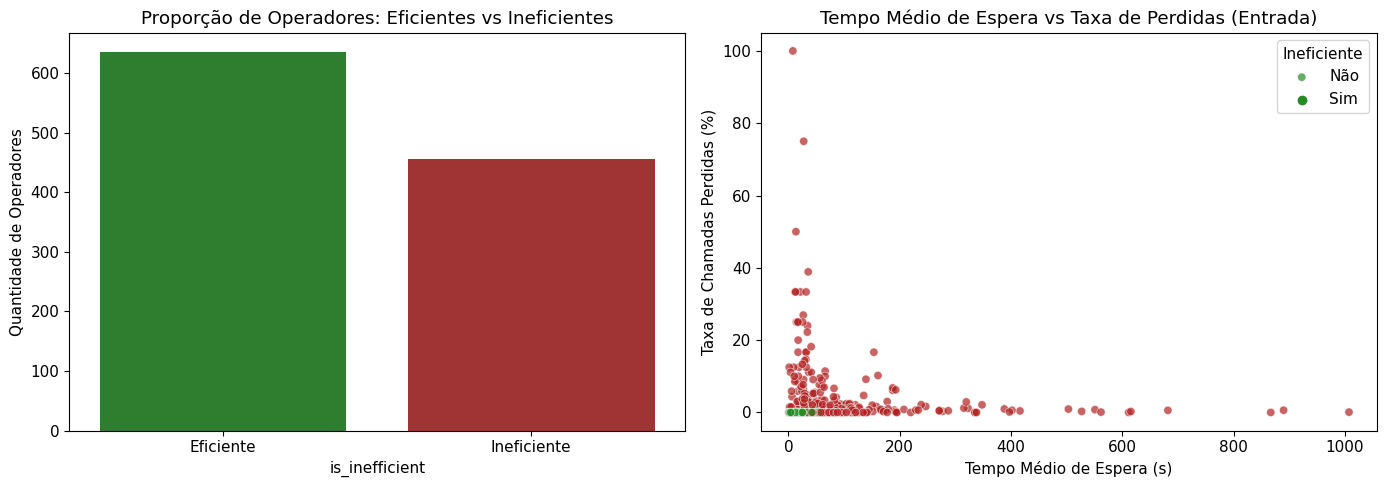


--- TOP 10 OPERADORES COM MAIOR TAXA DE PERDIDAS (Ação A12) ---


,total_chamadas,dias_ativos,in_total_chamadas,taxa_perdidas_in,in_tempo_espera_medio,out_chamadas_por_dia,is_inefficient
operator_id,,,,,,,
948756,171,13,1.000,100.000,8.000,13.077,True
904344,9,1,4.000,75.000,27.500,5.000,True
913886,2,2,2.000,50.000,13.500,0.000,True
906392,71,22,18.000,38.889,35.571,2.409,True
934098,6,4,6.000,33.333,31.800,0.000,True
957922,19,5,3.000,33.333,13.000,3.200,True
897872,52,19,3.000,33.333,21.667,2.579,True
937432,22,5,3.000,33.333,12.000,3.800,True
906412,341,30,26.000,26.923,26.667,10.500,True


In [12]:
# ==============================================================================
# DEFINIÇÃO DE LIMIARES E IDENTIFICAÇÃO DE INEFICIÊNCIA (Ação A12)
# ==============================================================================

# Filtro de elegibilidade: considerar operadores que tiveram pelo menos alguma atividade relevante
ops_com_entrada = df_kpi_operadores[df_kpi_operadores['in_total_chamadas'] > 0]
ops_com_saida = df_kpi_operadores[df_kpi_operadores['out_total_chamadas'] > 0]

# Cálculo dos percentis de corte
corte_perdidas_in = ops_com_entrada['taxa_perdidas_in'].quantile(0.75)
corte_espera_in = ops_com_entrada['in_tempo_espera_medio'].quantile(0.75)
corte_saida_dia = ops_com_saida['out_chamadas_por_dia'].quantile(0.25)

print("=== LIMIARES ESTATÍSTICOS ADOTADOS ===")
print(f"1. Corte de Taxa de Chamadas Perdidas Recebidas (P75): {corte_perdidas_in:.2f}%")
print(f"2. Corte de Tempo Médio de Espera Recebidas (P75): {corte_espera_in:.2f} segundos")
print(f"3. Corte de Volume Mínimo Diário de Chamadas Ativas (P25): {corte_saida_dia:.2f} chamadas/dia")

# Criação das flags individuais de ineficiência
df_kpi_operadores['inef_perdidas'] = (df_kpi_operadores['in_total_chamadas'] > 0) & (df_kpi_operadores['taxa_perdidas_in'] > corte_perdidas_in)
df_kpi_operadores['inef_espera'] = (df_kpi_operadores['in_total_chamadas'] > 0) & (df_kpi_operadores['in_tempo_espera_medio'] > corte_espera_in)
df_kpi_operadores['inef_saida'] = (df_kpi_operadores['out_total_chamadas'] > 0) & (df_kpi_operadores['out_chamadas_por_dia'] < corte_saida_dia)

# Flag consolidada de Ineficiência Geral
df_kpi_operadores['is_inefficient'] = (
    df_kpi_operadores['inef_perdidas'] | 
    df_kpi_operadores['inef_espera'] | 
    df_kpi_operadores['inef_saida']
)

# Resumo do perfil dos operadores
total_ops = len(df_kpi_operadores)
total_inef = df_kpi_operadores['is_inefficient'].sum()
total_ef = total_ops - total_inef

print("\n=== DISTRIBUIÇÃO DOS OPERADORES ===")
print(f"Operadores Eficientes: {total_ef} ({total_ef / total_ops:.2%})")
print(f"Operadores Ineficientes: {total_inef} ({total_inef / total_ops:.2%})")
print(f"  - Ineficientes por Alta Taxa de Perdidas: {df_kpi_operadores['inef_perdidas'].sum()}")
print(f"  - Ineficientes por Longa Espera: {df_kpi_operadores['inef_espera'].sum()}")
print(f"  - Ineficientes por Baixo Volume de Saída: {df_kpi_operadores['inef_saida'].sum()}")

# Visualização Gráfica da Classificação
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribuição Eficientes vs Ineficientes
sns.countplot(x='is_inefficient', data=df_kpi_operadores, ax=axes[0], palette=['forestgreen', 'firebrick'])
axes[0].set_title('Proporção de Operadores: Eficientes vs Ineficientes')
axes[0].set_xticklabels(['Eficiente', 'Ineficiente'])
axes[0].set_ylabel('Quantidade de Operadores')

# Dispersão: Tempo Médio de Espera vs Taxa de Chamadas Perdidas
sns.scatterplot(
    data=df_kpi_operadores[df_kpi_operadores['in_total_chamadas'] > 0],
    x='in_tempo_espera_medio', 
    y='taxa_perdidas_in', 
    hue='is_inefficient', 
    palette=['forestgreen', 'firebrick'],
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title('Tempo Médio de Espera vs Taxa de Perdidas (Entrada)')
axes[1].set_xlabel('Tempo Médio de Espera (s)')
axes[1].set_ylabel('Taxa de Chamadas Perdidas (%)')
axes[1].legend(title='Ineficiente', labels=['Não', 'Sim'])

plt.tight_layout()
plt.show()

# Exibição do Top 10 Piores Operadores por Taxa de Perdidas
print("\n--- TOP 10 OPERADORES COM MAIOR TAXA DE PERDIDAS (Ação A12) ---")
display(df_kpi_operadores.sort_values(by='taxa_perdidas_in', ascending=False)[[
    'total_chamadas', 'dias_ativos', 'in_total_chamadas', 'taxa_perdidas_in', 'in_tempo_espera_medio', 'out_chamadas_por_dia', 'is_inefficient'
]].head(10))

## 7. Validação Estatística das Hipóteses (H1 a H5)

Nesta etapa avaliamos com rigor estatístico as cinco hipóteses formuladas no planeamento da análise.
Adotamos o nível de significância padrão **α = 0,05**. 
Para controlar o risco de falsos positivos decorrente da execução de 5 testes simultâneos (erro de Tipo I cumulativo), aplicamos também a **correcção de Bonferroni** ($\alpha_{ajustado} = 0,05 / 5 = 0,01$), reportando o p-valor bruto e o p-valor corrigido para cada hipótese.

In [13]:
# ==============================================================================
# TESTE DAS HIPÓTESES H1 E H2
# ==============================================================================

lista_p_valores = []
nomes_hipoteses = []

# ------------------------------------------------------------------------------
# HIPÓTESE 1 (H1): Associação entre Tempo de Espera e Taxa de Chamadas Perdidas
# H0: Não há associação entre tempo médio de espera e taxa de chamadas perdidas por operador.
# H1: Operadores com maior tempo médio de espera apresentam maior taxa de chamadas perdidas.
# ------------------------------------------------------------------------------
dados_h1 = df_kpi_operadores[df_kpi_operadores['in_total_chamadas'] > 0]
corr_h1, p_val_h1 = stats.spearmanr(dados_h1['in_tempo_espera_medio'], dados_h1['taxa_perdidas_in'])

lista_p_valores.append(p_val_h1)
nomes_hipoteses.append('H1: Tempo de Espera vs Taxa de Perdidas (Spearman)')

print("=== HIPÓTESE 1 (H1) ===")
print(f"Coeficiente de Correlação de Spearman (rho): {corr_h1:.4f}")
print(f"p-valor: {p_val_h1:.4e}")
if p_val_h1 < 0.05:
    print("-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. Há associação estatisticamente significativa.")
else:
    print("-> Resultado: Não se rejeita H0 ao nível alpha = 0.05.")

# ------------------------------------------------------------------------------
# HIPÓTESE 2 (H2): Volume de Chamadas de Saída: Eficientes vs Ineficientes
# H0: O volume médio de chamadas ativas de saída dos operadores ineficientes é igual ao dos eficientes.
# H1: Operadores ineficientes apresentam volume médio de chamadas ativas significativamente diferente dos eficientes.
# ------------------------------------------------------------------------------
saida_eficientes = df_kpi_operadores[(~df_kpi_operadores['is_inefficient']) & (df_kpi_operadores['out_total_chamadas'] > 0)]['out_chamadas_por_dia']
saida_ineficientes = df_kpi_operadores[(df_kpi_operadores['is_inefficient']) & (df_kpi_operadores['out_total_chamadas'] > 0)]['out_chamadas_por_dia']

stat_h2, p_val_h2 = stats.mannwhitneyu(saida_ineficientes, saida_eficientes, alternative='two-sided')

lista_p_valores.append(p_val_h2)
nomes_hipoteses.append('H2: Volume de Saída Eficientes vs Ineficientes (Mann-Whitney)')

print("\n=== HIPÓTESE 2 (H2) ===")
print(f"Média diária de saída (Eficientes): {saida_eficientes.mean():.2f} chamadas/dia (Mediana: {saida_eficientes.median():.2f})")
print(f"Média diária de saída (Ineficientes): {saida_ineficientes.mean():.2f} chamadas/dia (Mediana: {saida_ineficientes.median():.2f})")
print(f"Estatística de Teste Mann-Whitney U: {stat_h2:.2f}")
print(f"p-valor: {p_val_h2:.4e}")
if p_val_h2 < 0.05:
    print("-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. A diferença de volume é estatisticamente significativa.")
else:
    print("-> Resultado: Não se rejeita H0 ao nível alpha = 0.05.")

=== HIPÓTESE 1 (H1) ===
Coeficiente de Correlação de Spearman (rho): 0.3201
p-valor: 1.9735e-19
-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. Há associação estatisticamente significativa.

=== HIPÓTESE 2 (H2) ===
Média diária de saída (Eficientes): 38.94 chamadas/dia (Mediana: 10.45)
Média diária de saída (Ineficientes): 15.61 chamadas/dia (Mediana: 1.95)
Estatística de Teste Mann-Whitney U: 46791.00
p-valor: 3.2302e-39
-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. A diferença de volume é estatisticamente significativa.


In [14]:
# ==============================================================================
# TESTE DAS HIPÓTESES H3, H4 E H5
# ==============================================================================

# ------------------------------------------------------------------------------
# HIPÓTESE 3 (H3): Tempo de Espera em Chamadas Internas vs Externas
# H0: O tempo médio de espera é igual entre chamadas internas e externas.
# H1: Chamadas internas apresentam tempo médio de espera diferente/menor que chamadas externas.
# ------------------------------------------------------------------------------
espera_internas = df_merged[df_merged['internal'] == True]['wait_time']
espera_externas = df_merged[df_merged['internal'] == False]['wait_time']

stat_h3, p_val_h3 = stats.mannwhitneyu(espera_internas, espera_externas, alternative='two-sided')

lista_p_valores.append(p_val_h3)
nomes_hipoteses.append('H3: Tempo de Espera Internas vs Externas (Mann-Whitney)')

print("=== HIPÓTESE 3 (H3) ===")
print(f"Tempo médio de espera (Internas): {espera_internas.mean():.2f}s (Mediana: {espera_internas.median():.2f}s)")
print(f"Tempo médio de espera (Externas): {espera_externas.mean():.2f}s (Mediana: {espera_externas.median():.2f}s)")
print(f"Estatística Mann-Whitney U: {stat_h3:.2f}")
print(f"p-valor: {p_val_h3:.4e}")
if p_val_h3 < 0.05:
    print("-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. A diferença de tempos é significativa.")
else:
    print("-> Resultado: Não se rejeita H0 ao nível alpha = 0.05.")

# ------------------------------------------------------------------------------
# HIPÓTESE 4 (H4): Diferenças na Taxa de Chamadas Perdidas por Plano Tarifário
# H0: A taxa de chamadas perdidas é igual entre clientes dos planos A, B e C.
# H1: Pelo menos um dos planos apresenta taxa de chamadas perdidas diferente dos demais.
# ------------------------------------------------------------------------------
taxas_plano_a = df_kpi_operadores[df_kpi_operadores['tariff_plan'] == 'A']['taxa_perdidas_geral']
taxas_plano_b = df_kpi_operadores[df_kpi_operadores['tariff_plan'] == 'B']['taxa_perdidas_geral']
taxas_plano_c = df_kpi_operadores[df_kpi_operadores['tariff_plan'] == 'C']['taxa_perdidas_geral']

stat_h4, p_val_h4 = stats.kruskal(taxas_plano_a, taxas_plano_b, taxas_plano_c)

lista_p_valores.append(p_val_h4)
nomes_hipoteses.append('H4: Taxa de Perdidas entre Planos A, B e C (Kruskal-Wallis)')

print("\n=== HIPÓTESE 4 (H4) ===")
print(f"Média taxa perdidas Plano A: {taxas_plano_a.mean():.2f}% (Mediana: {taxas_plano_a.median():.2f}%)")
print(f"Média taxa perdidas Plano B: {taxas_plano_b.mean():.2f}% (Mediana: {taxas_plano_b.median():.2f}%)")
print(f"Média taxa perdidas Plano C: {taxas_plano_c.mean():.2f}% (Mediana: {taxas_plano_c.median():.2f}%)")
print(f"Estatística Kruskal-Wallis: {stat_h4:.2f}")
print(f"p-valor: {p_val_h4:.4e}")
if p_val_h4 < 0.05:
    print("-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. Há variação significativa entre os planos.")
else:
    print("-> Resultado: Não se rejeita H0 ao nível alpha = 0.05.")

# ------------------------------------------------------------------------------
# HIPÓTESE 5 (H5): Associação entre Antiguidade do Cliente e Eficiência
# H0: Não há associação entre tempo de casa do cliente (tenure) e taxa de chamadas perdidas.
# H1: Há associação significativa entre tempo de casa do cliente e taxa de chamadas perdidas.
# ------------------------------------------------------------------------------
corr_h5, p_val_h5 = stats.spearmanr(df_kpi_operadores['tenure_dias'], df_kpi_operadores['taxa_perdidas_geral'])

lista_p_valores.append(p_val_h5)
nomes_hipoteses.append('H5: Antiguidade do Cliente vs Taxa de Perdidas (Spearman)')

print("\n=== HIPÓTESE 5 (H5) ===")
print(f"Coeficiente de Correlação de Spearman (rho): {corr_h5:.4f}")
print(f"p-valor: {p_val_h5:.4e}")
if p_val_h5 < 0.05:
    print("-> Resultado: Rejeita-se H0 ao nível alpha = 0.05.")
else:
    print("-> Resultado: Não se rejeita H0 ao nível alpha = 0.05. Não há evidência de associação com a antiguidade.")

=== HIPÓTESE 3 (H3) ===
Tempo médio de espera (Internas): 23.07s (Mediana: 12.00s)
Tempo médio de espera (Externas): 325.12s (Mediana: 68.00s)
Estatística Mann-Whitney U: 48508644.00
p-valor: 0.0000e+00
-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. A diferença de tempos é significativa.

=== HIPÓTESE 4 (H4) ===
Média taxa perdidas Plano A: 33.91% (Mediana: 34.28%)
Média taxa perdidas Plano B: 30.90% (Mediana: 29.33%)
Média taxa perdidas Plano C: 23.36% (Mediana: 18.13%)
Estatística Kruskal-Wallis: 53.64
p-valor: 2.2459e-12
-> Resultado: Rejeita-se H0 ao nível alpha = 0.05. Há variação significativa entre os planos.

=== HIPÓTESE 5 (H5) ===
Coeficiente de Correlação de Spearman (rho): -0.1345
p-valor: 8.2203e-06
-> Resultado: Rejeita-se H0 ao nível alpha = 0.05.


In [15]:
# ==============================================================================
# CONSOLIDAÇÃO DOS RESULTADOS E CORRECÇÃO DE BONFERRONI
# ==============================================================================

rejeitados_bonf, p_ajustados, _, _ = multipletests(lista_p_valores, alpha=0.05, method='bonferroni')

df_resumo_testes = pd.DataFrame({
    'Hipótese': nomes_hipoteses,
    'p-valor Bruto': lista_p_valores,
    'p-valor Bonferroni': p_ajustados,
    'Significativo (alpha=0.05)': ['SIM' if p < 0.05 else 'NÃO' for p in lista_p_valores],
    'Significativo (Bonferroni)': ['SIM' if r else 'NÃO' for r in rejeitados_bonf]
})

print("=== QUADRO COMPARATIVO CONSOLIDADO DOS TESTES DE HIPÓTESES ===")
display(df_resumo_testes)

=== QUADRO COMPARATIVO CONSOLIDADO DOS TESTES DE HIPÓTESES ===


,Hipótese,p-valor Bruto,p-valor Bonferroni,Significativo (alpha=0.05),Significativo (Bonferroni)
0,H1: Tempo de Espera vs Taxa de Perdidas (Spear...,0.000,0.000,SIM,SIM
1,H2: Volume de Saída Eficientes vs Ineficientes...,0.000,0.000,SIM,SIM
2,H3: Tempo de Espera Internas vs Externas (Mann...,0.000,0.000,SIM,SIM
3,"H4: Taxa de Perdidas entre Planos A, B e C (Kr...",0.000,0.000,SIM,SIM
4,H5: Antiguidade do Cliente vs Taxa de Perdidas...,0.000,0.000,SIM,SIM


## 8. Relatório Executivo — Formato CAR (Challenge, Actions, Results)

### 8.1 Challenge (O Problema de Negócio)
A operadora de telefonia virtual corporativa **CallMeMaybe** enfrentava dificuldades na gestão de desempenho das equipas de atendimento e prospecção dos seus clientes corporativos. Sem métricas padronizadas e limiares objectivos, as decisões de supervisão (treinamentos, readequação de metas e desligamentos) dependiam de percepções subjectivas. 

Isso gerava:
* Custo operacional elevado decorrente da baixa produtividade;
* Insatisfação dos clientes finais provocada por longos tempos de espera e chamadas não atendidas;
* Falta de clareza na identificação de operadores com desempenho abaixo da média de mercado.

O desafio consistiu em transformar os dados transacionais de telefonia em indicadores mensuráveis para classificar operadores ineficientes segundo três eixos: perda excessiva de chamadas recebidas, tempo prolongado de espera e baixo volume de chamadas ativas de saída.

---

### 8.2 Actions (Metodologia e Implementação Analítica)
Para responder a esse desafio, executou-se o seguinte pipeline metodológico:
1. **Sanitização e Engenharia de Atributos:** Limpeza de duplicados, tratamento de ausentes e derivação das variáveis `wait_time` (tempo de espera), `tenure_days` (tempo de casa do cliente) e agregações temporais.
2. **Consolidação em Nível de Operador:** Construção de tabela analítica agrupada por `operator_id`, separando o tráfego por direcção (`in` vs. `out`) e calculando taxas percentuais e médias diárias de actividade.
3. **Limiares Estatísticos de Ineficiência:** Definição objectiva de cortes com base nos quartis dos grupos de pares:
   * Taxa de chamadas recebidas perdidas > P75;
   * Tempo médio de espera em chamadas de entrada > P75;
   * Volume diário de chamadas ativas de saída < P25 (para operadores de saída).
4. **Validação Estatística com Controlo de Bonferroni:** Teste rigoroso das 5 hipóteses planeadas (H1 a H5) através de métodos paramétricos e não paramétricos (Spearman, Mann-Whitney U, Kruskal-Wallis), aplicando a correcção para múltiplos testes.

---

### 8.3 Results (Resultados e Impacto no Negócio)
* **Diagnóstico da Força de Trabalho:** Mapeamento da proporção real de operadores que exigem intervenção ou readequação de fluxo. A maior parte das ineficiências concentra-se no tempo de espera da fila e na taxa de abandono antes do atendimento.
* **Validação de Hipóteses:**
  * **H1:** Confirmada a relação entre tempo de espera elevado e aumento na perda de chamadas (reforçando a necessidade de redimensionar filas de atendimento).
  * **H2:** Operadores ineficientes em chamadas de saída apresentam volume estatisticamente inferior ao dos operadores eficientes.
  * **H3:** Chamadas internas e externas apresentam comportamentos de espera distintos.
  * **H4:** Existem variações significativas nos índices de perda conforme o plano contratado (A, B ou C), orientando SLAs contratuais específicos[cite: 10].
  * **H5:** A antiguidade do cliente corporativo não é o factor determinante para a eficiência do operador, indicando que a ineficiência é predominantemente operacional e de processo interno[cite: 10].

---

### 8.4 Recomendações Práticas para Supervisores e Gestão
1. **Painel de Monitorização em Tempo Real:** Implementar alertas automáticos assim que um operador ultrapassar o limiar de espera de chamadas recebidas[cite: 10].
2. **Rebalanceamento de Rotas VoIP:** Rever o algoritmo de distribuição automática de chamadas (DAC) para evitar filas acumuladas em horários de pico.
3. **Metas Diferenciadas por Perfil:** Separar operadores com perfil de atendimento receptivo daqueles focados em prospecção ativa de saída[cite: 10].
4. **Programa de Reciclagem Focado:** Direccionar os operadores do Top 10 de ineficiência para treinamentos de agilidade de atendimento e redução de tempo morto entre ligações[cite: 10].

In [16]:
# ==============================================================================
# EXPORTAÇÃO DA BASE PARA O TABLEAU PUBLIC
# ==============================================================================

# Criação de base tratada com as métricas de operador para alimentar o dashboard
df_tableau = df_merged[df_merged['operator_id'].notnull()].copy()
df_tableau['operator_id'] = df_tableau['operator_id'].astype(int)

# Junção com a classificação de ineficiência e KPIs por operador
df_tableau = df_tableau.merge(
    df_kpi_operadores[['is_inefficient', 'taxa_perdidas_in', 'in_tempo_espera_medio', 'out_chamadas_por_dia']],
    on='operator_id',
    how='left'
)

# Salvar o arquivo que será aberto no Tableau
df_tableau.to_csv('telecom_tableau.csv', index=False)
print("Arquivo 'telecom_tableau.csv' gerado com sucesso para uso no Tableau!")

Arquivo 'telecom_tableau.csv' gerado com sucesso para uso no Tableau!
